In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
from scipy.optimize import least_squares
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup

np.random.seed(42)

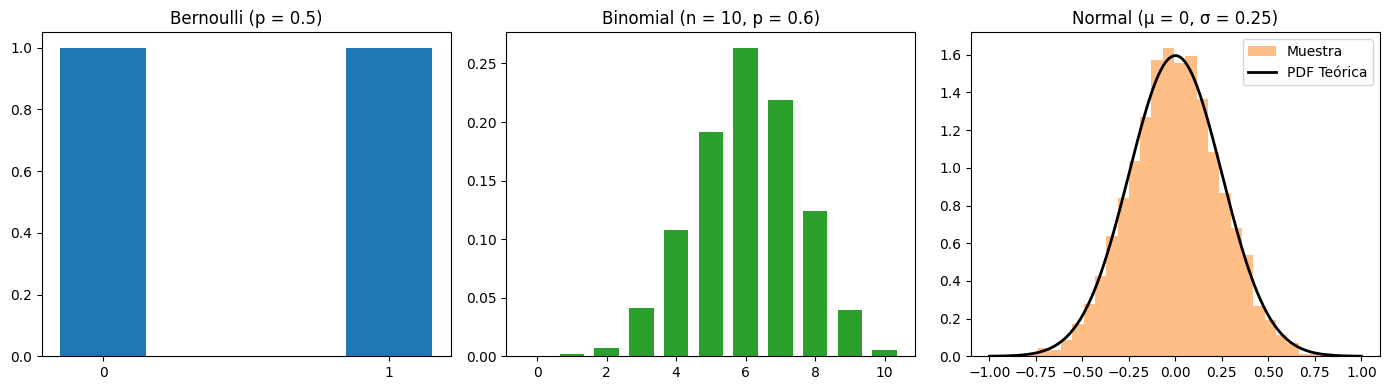

In [2]:
# ==============================================================================
# 1. SIMULACIÓN DE DISTRIBUCIONES FUNDAMENTALES
# ==============================================================================
N_vis = 5000

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Bernoulli
B_vis = st.bernoulli.rvs(p=0.5, size=N_vis)
axes[0].hist(B_vis, bins=[-0.25, 0.25, 0.75, 1.25], density=True, rwidth=0.6, color="#1f77b4")
axes[0].set_title("Bernoulli (p = 0.5)")
axes[0].set_xticks([0, 1])

# Binomial
Bin_vis = st.binom.rvs(n=10, p=0.6, size=N_vis)
axes[1].hist(Bin_vis, bins=np.arange(12) - 0.5, density=True, rwidth=0.7, color="#2ca02c")
axes[1].set_title("Binomial (n = 10, p = 0.6)")

# Gaussiana
G_vis = st.norm.rvs(loc=0, scale=0.25, size=N_vis)
x_grid = np.linspace(-1, 1, 200)
axes[2].hist(G_vis, bins=30, density=True, alpha=0.5, color="#ff7f0e", label="Muestra")
axes[2].plot(x_grid, st.norm.pdf(x_grid, loc=0, scale=0.25), "k-", lw=2, label="PDF Teórica")
axes[2].set_title("Normal (μ = 0, σ = 0.25)")
axes[2].legend()

plt.tight_layout()
plt.savefig("distribuciones_simuladas.png", dpi=150)
plt.show()

=== OPCIONES EUROPEAS (M = 4 períodos) ===
Call Exacto: 10.5334 | Monte Carlo: 10.5300 (IC 95%: [10.4755, 10.5845])
Put Exacto:  1.0096 | Monte Carlo: 1.0168 (IC 95%: [0.9987, 1.0349])


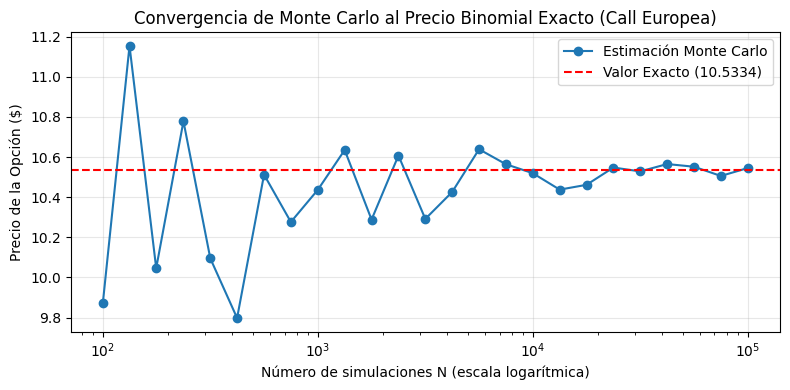

In [3]:
# ==============================================================================
# 2. VALUACIÓN DE OPCIONES EUROPEAS: FÓRMULA BINOMIAL VS. MONTE CARLO
# ==============================================================================
def valorar_europea_binomial(S0, K, r, T, M, u, d, tipo="call"):
    """Valuación exacta mediante esperanza bajo medida neutral al riesgo."""
    r_eff = (1 + r * T) ** (1 / M) - 1
    p = ((1 + r_eff) - d) / (u - d)

    # Estados terminales posibles: j subidas en M pasos
    j = np.arange(M + 1)
    ST = S0 * (u ** j) * (d ** (M - j))
    probs = st.binom.pmf(j, M, p)

    payoff = np.maximum(ST - K, 0) if tipo == "call" else np.maximum(K - ST, 0)
    precio = np.sum(probs * payoff) * ((1 + r_eff) ** (-M))
    return precio


def valorar_europea_mc(S0, K, r, T, M, u, d, N=100_000, tipo="call"):
    """Valuación por simulación de Monte Carlo vectorizada con intervalo de confianza."""
    r_eff = (1 + r * T) ** (1 / M) - 1
    p = ((1 + r_eff) - d) / (u - d)

    subidas = st.binom.rvs(M, p, size=N)
    ST = S0 * (u ** subidas) * (d ** (M - subidas))

    payoff = np.maximum(ST - K, 0) if tipo == "call" else np.maximum(K - ST, 0)
    payoffs_descontados = payoff * ((1 + r_eff) ** (-M))

    precio_mc = np.mean(payoffs_descontados)
    error_estandar = np.std(payoffs_descontados, ddof=1) / np.sqrt(N)
    ic_95 = (precio_mc - 1.96 * error_estandar, precio_mc + 1.96 * error_estandar)
    return precio_mc, ic_95


# Parámetros del contrato
S0, K, r, T, M = 100, 95, 0.05, 1.0, 4
u, d = 1.05, 0.94

call_exacto = valorar_europea_binomial(S0, K, r, T, M, u, d, tipo="call")
call_mc, ic_call = valorar_europea_mc(S0, K, r, T, M, u, d, N=100_000, tipo="call")

put_exacto = valorar_europea_binomial(S0, K, r, T, M, u, d, tipo="put")
put_mc, ic_put = valorar_europea_mc(S0, K, r, T, M, u, d, N=100_000, tipo="put")

print("=== OPCIONES EUROPEAS (M = 4 períodos) ===")
print(f"Call Exacto: {call_exacto:.4f} | Monte Carlo: {call_mc:.4f} (IC 95%: [{ic_call[0]:.4f}, {ic_call[1]:.4f}])")
print(f"Put Exacto:  {put_exacto:.4f} | Monte Carlo: {put_mc:.4f} (IC 95%: [{ic_put[0]:.4f}, {ic_put[1]:.4f}])")

# Gráfica de convergencia de Monte Carlo
Ns = np.logspace(2, 5, 25, dtype=int)
estimaciones = [valorar_europea_mc(S0, K, r, T, M, u, d, N=n, tipo="call")[0] for n in Ns]

plt.figure(figsize=(8, 4))
plt.plot(Ns, estimaciones, marker="o", label="Estimación Monte Carlo")
plt.axhline(call_exacto, color="red", linestyle="--", label=f"Valor Exacto ({call_exacto:.4f})")
plt.xscale("log")
plt.title("Convergencia de Monte Carlo al Precio Binomial Exacto (Call Europea)")
plt.xlabel("Número de simulaciones N (escala logarítmica)")
plt.ylabel("Precio de la Opción ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("convergencia_montecarlo.png", dpi=150)
plt.show()

In [4]:
# ==============================================================================
# 3. OPCIONES EXÓTICAS (DEPENDIENTES DE LA TRAYECTORIA - VECTORIZADAS)
# ==============================================================================
def simular_trayectorias(S0, r, T, M, u, d, N=100_000):
    """Genera matriz (N x M+1) con trayectorias completas del activo subyacente."""
    r_eff = (1 + r * T) ** (1 / M) - 1
    p = ((1 + r_eff) - d) / (u - d)

    # Pasos aleatorios: 1 = subida (u), 0 = bajada (d)
    pasos = st.bernoulli.rvs(p, size=(N, M))
    factores = np.where(pasos == 1, u, d)

    trayectorias = np.empty((N, M + 1))
    trayectorias[:, 0] = S0
    trayectorias[:, 1:] = S0 * np.cumprod(factores, axis=1)
    return trayectorias, r_eff


trayectorias, r_eff = simular_trayectorias(S0, r, T, M, u, d, N=100_000)

# 3a. Opción Asiática (promedio aritmético de la trayectoria)
promedio_trayectoria = np.mean(trayectorias, axis=1)
payoff_asiatica = np.maximum(promedio_trayectoria - K, 0)
precio_asiatica = np.mean(payoff_asiatica) * ((1 + r_eff) ** (-M))

# 3b. Opción Barrera Up-and-Out (se cancela si supera la barrera B en cualquier instante)
B = 115  # Barrera activa dentro del rango alcanzable (S0 * u^4 = 121.55)
supera_barrera = np.any(trayectorias > B, axis=1)
payoff_barrera = np.where(supera_barrera, 0.0, np.maximum(trayectorias[:, -1] - K, 0))
precio_barrera = np.mean(payoff_barrera) * ((1 + r_eff) ** (-M))

print("\n=== OPCIONES EXÓTICAS (MONTE CARLO VECTORIZADO) ===")
print(f"Asian Call Option (promedio):           {precio_asiatica:.4f}")
print(f"Up-and-Out Call Option (Barrera B={B}): {precio_barrera:.4f}")



=== OPCIONES EXÓTICAS (MONTE CARLO VECTORIZADO) ===
Asian Call Option (promedio):           7.4031
Up-and-Out Call Option (Barrera B=115): 4.5157


In [5]:
# ==============================================================================
# 4. OPCIONES AMERICANAS (PROGRAMACIÓN DINÁMICA / INDUCCIÓN HACIA ATRÁS)
# ==============================================================================
def valorar_americana_put(S0, K, r, T, M, u, d):
    """Inducción hacia atrás en árbol binomial considerando ejercicio anticipado óptimo."""
    r_eff = (1 + r * T) ** (1 / M) - 1
    p = ((1 + r_eff) - d) / (u - d)
    q = 1 - p

    # Valores en el vencimiento t = M
    j = np.arange(M + 1)
    S_T = S0 * (u ** j) * (d ** (M - j))
    V = np.maximum(K - S_T, 0)

    # Retroceso nodo por nodo desde M-1 hasta 0
    for i in range(M - 1, -1, -1):
        j_i = np.arange(i + 1)
        S_i = S0 * (u ** j_i) * (d ** (i - j_i))
        valor_continuacion = (p * V[1:i + 2] + q * V[0:i + 1]) / (1 + r_eff)
        valor_ejercicio = np.maximum(K - S_i, 0)
        V = np.maximum(valor_continuacion, valor_ejercicio)

    return V[0]


put_americana = valorar_americana_put(S0, K, r, T, M, u, d)
print("\n=== OPCIÓN AMERICANA (ÁRBOL BINOMIAL) ===")
print(f"Put Americana: {put_americana:.4f} (vs. Put Europea: {put_exacto:.4f})")


=== OPCIÓN AMERICANA (ÁRBOL BINOMIAL) ===
Put Americana: 1.1555 (vs. Put Europea: 1.0096)


In [6]:
# ==============================================================================
# 5. CALIBRACIÓN NO LINEAL CON JACOBIANO ANALÍTICO
# ==============================================================================
def modelo_no_lineal(x, u):
    return x[0] * (u ** 2 + x[1] * u) / (u ** 2 + x[2] * u + x[3])

def residuales(x, u, y):
    return modelo_no_lineal(x, u) - y

def jacobiano_analitico(x, u, y):
    J = np.empty((u.size, x.size))
    den = u ** 2 + x[2] * u + x[3]
    num = u ** 2 + x[1] * u
    J[:, 0] = num / den
    J[:, 1] = x[0] * u / den
    J[:, 2] = -x[0] * num * u / (den ** 2)
    J[:, 3] = -x[0] * num / (den ** 2)
    return J

u_obs = np.array([4.0, 2.0, 1.0, 0.5, 0.25, 0.167, 0.125, 0.1, 0.0833, 0.0714, 0.0625])
y_obs = np.array([0.1957, 0.1947, 0.1735, 0.16, 0.0844, 0.0627, 0.0456, 0.0342, 0.0323, 0.0235, 0.0246])
x0 = np.array([2.5, 3.9, 4.15, 3.9])

res = least_squares(residuales, x0, jac=jacobiano_analitico, bounds=(0, 100), args=(u_obs, y_obs))
print("\n=== CALIBRACIÓN NO LINEAL (LEAST SQUARES + JACOBIANO) ===")
print(f"Parámetros óptimos: {np.round(res.x, 4)} | Costo final: {res.cost:.2e}")


=== CALIBRACIÓN NO LINEAL (LEAST SQUARES + JACOBIANO) ===
Parámetros óptimos: [0.1928 0.1913 0.1231 0.1361] | Costo final: 1.54e-04


In [7]:
# ==============================================================================
# 6. EXTRACCIÓN DE CADENA DE OPCIONES DESDE YAHOO! FINANCE
# ==============================================================================
def obtener_cadena_opciones(ticker="^RUT"):
    url = f"https://finance.yahoo.com/quote/{ticker}/options?p={ticker}"
    headers = {"User-Agent": "Mozilla/5.0"}
    try:
        resp = requests.get(url, headers=headers, timeout=5)
        soup = BeautifulSoup(resp.text, "html.parser")
        tabla = soup.find("table")
        if tabla is None:
            raise ValueError("Tabla no disponible en respuesta HTML.")

        filas = []
        for tr in tabla.find("tbody").find_all("tr"):
            celdas = [td.text.strip() for td in tr.find_all("td") if td.text.strip()]
            if celdas:
                filas.append(celdas)
        return pd.DataFrame(filas)
    except Exception as e:
        print(f"\nNota de extracción web: {e}")
        return pd.DataFrame()

df_opciones = obtener_cadena_opciones("^RUT")
if not df_opciones.empty:
    print("\nPrimeras filas extraídas de opciones:")
    print(df_opciones.head())


Primeras filas extraídas de opciones:
                     0
0  There are no calls.
